# LASSI - Power Efficiency

**OLLAMA API** + **Argo Gateway API** Jupyter Notebook version

+ ***Post LASSI-Judge version with pass@k***
+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


In [2]:
!nvidia-smi

Thu Sep  4 03:46:55 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          Off |   00000000:99:00.0 Off |                    0 |
| N/A   33C    P0             32W /  250W |     124MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


## Setup

In [4]:
import os
import json
import csv
import time
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [5]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 100"]
    
    """

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # Enter source application to process through LASSI
    source_collection = "HeCBench"  # "Miniapps" "HeCBench"
    source_app = "layout"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    if make_script:
        app_name = app_folder_name
        file_name = "kernels"
    else:
        app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    verifyprompt = True  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            code_compiler = "make"
            code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
            # -arch=sm_89 for RTX 5000
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # For A100 on Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        # !! TODO - REVIEW: code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc80"  # "-fopenmp -O3 -c"
        # For RTX 5000 Ada on Linux x86_64:
        # code_compiler = "/opt/nvidia/hpc_sdk/Linux_x86_64/25.7/compilers/bin/nvc++" # "g++"
        # code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc89"  # "-fopenmp -O3"
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1
        # ****************************
        # ---> EXPERIMENT UPDATE FIELD - Now, automated:
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 200000)
    # model_coder = "gpt4olatest"  # (max token = 200000)
    # model_judge = "gpt4olatest"  # (max token = 200000)

    # -- FROM CEREBRAS
    model = "gpt-oss-120b"
    model_judge = "gpt-oss-120b"
    model_coder = "qwen-3-coder-480b"
    
    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
    # model_coder = "qwen3-coder:30b"  # context 262144
    # model = "gpt-oss:20b"
    # model_judge = "gpt-oss:20b"
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif model in ["gpt-oss-120b", "qwen-3-coder-480b"]:
        llm_source = "cerebras"
    elif ("GGUF" in model and "hf.co" not in model):
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "mtdTEST_" + model + "_" + app_folder_name + "_ee"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "trial_number",
        "timestamp",
        "experiment",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        "base_v1_optimization_methods",
        "base_v2_energy_J",
        "base_v2_avg_power_W",
        "base_v2_runtime_s",
        "base_v2_valid",
        "base_v2_selfcorrections",
        "base_v2_energy_diff",
        "base_v2_avg_power_diff",
        "base_v2_runtime_diff",
        "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES)

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 09-03-2025_t22_46_57
Application: layout

EE Refactoring: CUDA_ee

LLM Source: cerebras
Model: gpt-oss-120b
Model coder: qwen-3-coder-480b
Model judge: gpt-oss-120b
System Prompt Index: CUDA
Code file template: generated_codes/cerebras_gpt-oss-120b/promptset_CUDA/layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True



***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) ***** Trial #: 1



----- GPU Memory Status:
 GPU 0: 639 MiB used, 40320 MiB free, 40960 MiB total

----- GPU State:
clocks

Waiting for the system to settle down for 1 seconds...: 100%|██████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/layout/layout-cuda_main
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/layout
executable:  layout-cuda_main
Working directory: /home/cc/lassi/LASSI-EE/source_codes/HeCBench/layout
Execute command: ['./layout-cuda_main', '2500']

running: executable -  layout-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Average kernel execution time (AoS): 3088.64 (us)
PASS
Average kernel execution time (SoA): 909.57 (us)
PASS

----- < END: Standard Output > -----

GPU power data has been written to source_CUDA_gpu_net_power_results.csv


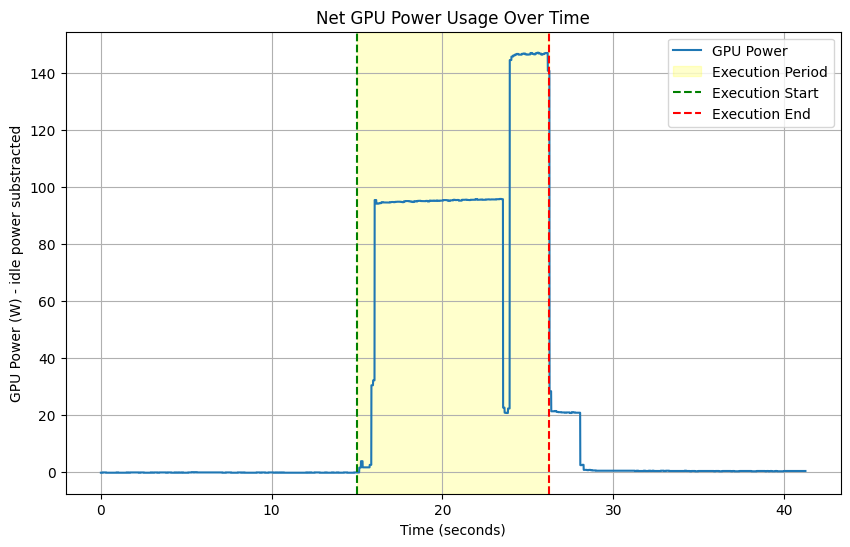

Start time: 15.0 -- End time: 26.248
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000297 kWh
  0.2972 Wh
  1070.01 J
Average GPU power: 95.20 W +/- 37.96 
 with sample standard deviation.
Net Energy During Exe Runtime:   1070.01 J
Code execution duration:  11.25 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 639 MiB used, 40320 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.38 W, P0



Measure system idle power...
Duration for idle time measurement: 11.25
GPU power data has been written to idle__gpu_net_power_results.csv


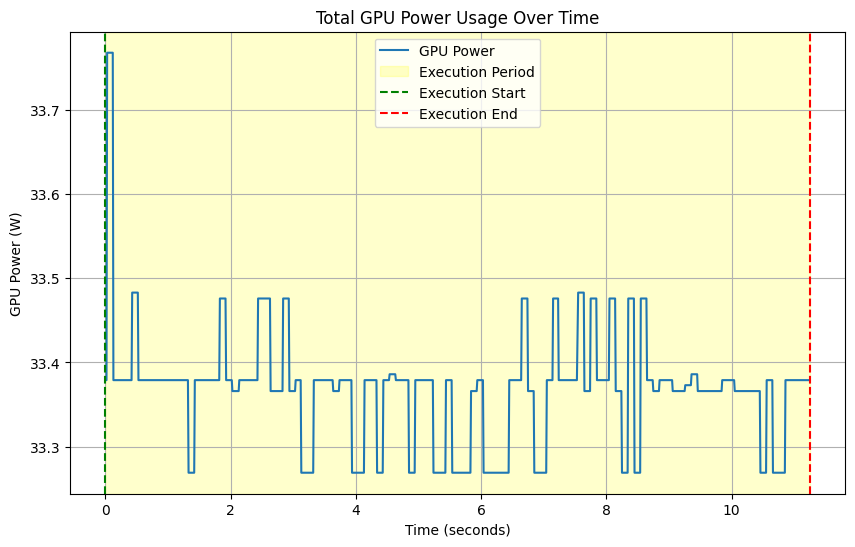

Start time: 0 -- End time: 11.248
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000104 kWh
  0.1043 Wh
  375.39 J
Average GPU power: 33.37 W +/- 0.07 
 with sample standard deviation.
Total Energy During Exe Runtime:   375.39 J
Code execution duration:  11.25 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


----- STARTING STAGE 1: STANDALONE BASE LLM REFACTORING  -----



--> ... prompt LLM to perform code analysis.




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
    You are a formal methods and parallel programming expert and you specialize in identifying key characteristics of a given CUDA code. The characteristics can be something like invariants (a property of the program state that is always true), properties, patterns, unit tests, etc. The goal is to use these characteristics to determine if a refactored version of the code provide the same general functionality. Your task is to:
    1. Identify underlying assumptions of the code
    2. Identify invariants
    3. Identify design patterns
    4. Identify memory access patterns
    5. Identify memory allocation/deallocation
    6. Other key characte

=====  
```json
{
  "assumptions": {
    "execution_environment": [
      "CUDA-capable GPU with compute capability sufficient for the launch configuration.",
      "Host system provides enough RAM to allocate input, output, and reference buffers."
    ],
    "input_parameters": [
      "The program is invoked with exactly one command‑line argument representing a positive integer (iterations).",
      "TREE_NUM (number of trees) is a multiple of GROUP_SIZE (256) and >= GROUP_SIZE."
    ],
    "data_layout": [
      "AppleTree struct stores TREE_SIZE (16384) integers contiguously per tree (Array‑of‑Structures).",
      "ApplesOnTrees struct stores TREE_NUM (16384) integers contiguously per tree (Structure‑of‑Arrays)."
    ],
    "kernel correctness": [
      "Each thread processes exactly one tree (gid) and sums TREE_SIZE elements belonging to that tree.",
      "The reference result is computed as the arithmetic series sum for each tree: Σ_{j=0}^{TREE_SIZE-1} (i * TREE_SIZE + j)."
    ]
  },
  "invariants": {
    "thread_index_range": "0 ≤ gid < TREE_NUM for every kernel launch (grid and block sizes guarantee this).",
    "output_buffer_size": "output buffer always holds TREE_NUM integers; each kernel writes exactly one integer per thread.",
    "input_buffer_size": "input buffer always holds TREE_NUM * TREE_SIZE integers; kernels only read within these bounds.",
    "reference_consistency": "The reference array remains unchanged after its initial computation; it is used for both AoS and SoA verification."
  },
  "design_patterns": {
    "template_kernel": "Both kernels are templated on treeSize, allowing compile‑time unrolling of the loop bound.",
    "restrict_qualifier": "Pointers are marked __restrict__ to inform the compiler that there is no aliasing, enabling better optimization.",
    "AoS_vs_SoA_benchmark": "The program implements a classic performance comparison between Array‑of‑Structures and Structure‑of‑Arrays data layouts.",
    "host‑device data transfer": "Explicit cudaMemcpy calls are used for staging data to/from the device.",
    "RAII‑like manual resource management": "All allocations (malloc, cudaMalloc) are paired with corresponding frees (free, cudaFree) before program exit."
  },
  "memory_access_patterns": {
    "AoSKernel": {
      "access_pattern": "Each thread reads TREE_SIZE consecutive integers from a single AppleTree instance (contiguous memory).",
      "coalescing": "Since each thread accesses a distinct AppleTree, the accesses are strided by TREE_SIZE (16384) ints, which is not coalesced across threads; each warp accesses memory from different rows of the 2‑D layout."
    },
    "SoAKernel": {
      "access_pattern": "Each thread reads TREE_SIZE integers that are spaced by TREE_NUM (the number of trees) in the input buffer, i.e., column‑wise access.",
      "coalescing": "Threads in a warp read consecutive memory locations because the inner loop index i iterates over the first dimension (trees) and gid is the column index; this yields fully coalesced reads."
    },
    "host_initialization": [
      "AoS data is filled row‑major (tree‑major) order.",
      "SoA data is filled column‑major (tree‑minor) order."
    ],
    "host‑to‑device transfers": "Both transfers copy the entire input buffer (TREE_NUM * TREE_SIZE * sizeof(int)) in a single cudaMemcpy, which is optimal for bandwidth."
  },
  "memory_allocation": {
    "host": {
      "data": "malloc(inputSize) – raw int array holding the entire dataset (both AoS and SoA).",
      "deviceResult": "malloc(outputSize) – host buffer for copying back kernel results.",
      "reference": "malloc(outputSize) – host buffer storing expected sums."
    },
    "device": {
      "inputBuffer": "cudaMalloc(inputSize) – device buffer holding the full dataset.",
      "outputBuffer": "cudaMalloc(outputSize) – device buffer for per‑tree sums."
    },
    "deallocation": {
      "device": [
        "cudaFree(inputBuffer)",
        "cudaFree(outputBuffer)"
      ],
      "host": [
        "free(deviceResult)",
        "free(reference)",
        "free(data)"
      ]
    }
  },
  "key_characteristics": {
    "performance_measurement": "Average kernel execution time is measured over a user‑specified number of iterations using std::chrono on the host.",
    "verification": "After each kernel run, the device results are copied back and compared element‑wise against the pre‑computed reference; any mismatch sets a fail flag.",
    "scalability": "The code assumes a fixed problem size (TREE_NUM = 16384, TREE_SIZE = 16384) but can be recompiled with different constants; grid size is derived from TREE_NUM / GROUP_SIZE.",
    "error_handling": [
      "Minimal; only checks command‑line argument count and basic parameter constraints.",
      "CUDA API return values are not checked."
    ],
    "compile‑time constants": [
      "TREE_NUM, TREE_SIZE, GROUP_SIZE are macro definitions; they affect both host and device code."
    ],
    "language features": [
      "C++11 (std::chrono, nullptr, etc.)",
      "CUDA extensions (<<<>>> launch syntax, __global__, __restrict__)."
    ]
  }
}
```  
=====



----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 0 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 1557)


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 

Refactor the following CUDA C++ code to optimize energy efficiency by reducing GPU energy consumption, while preserving all functionality.

[START OF CODE TO REFACTOR]
/**********************************************************************
* Copyright ©2013 Advanced Micro Devices, Inc. All rights reserved.
*
* Redistribution and use in source and binary forms, with or without modification, are permitted provided that the following conditions are met:
*
* Redistributions of source code must retain the above copyright notice, this list of conditions and the following disclaimer.
* Redistributions in binary form must reproduce the above copyright

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57/layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57
executable:  layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57
Execute command: ['./layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1', '2500']

running: executable -  layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Average kernel execution time (AoS): 3018.41 (us)
PASS
Average kern

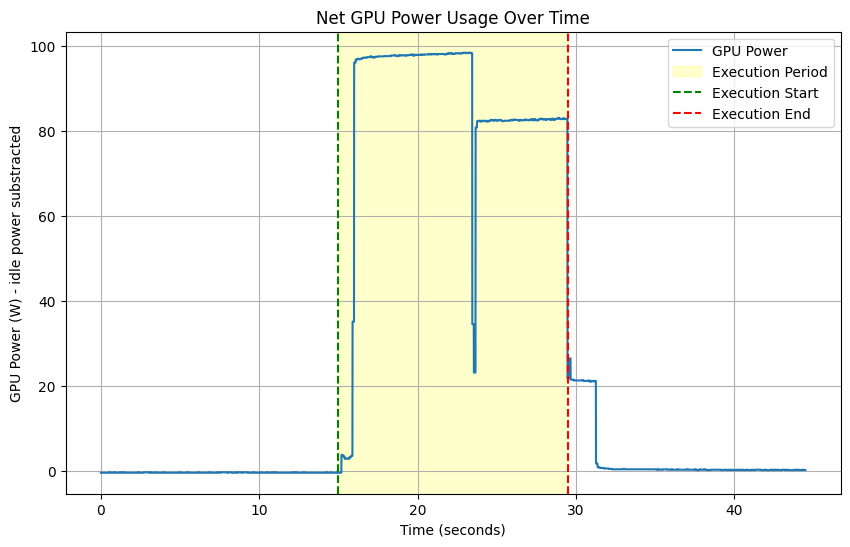

Start time: 15.0 -- End time: 29.49
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000339 kWh
  0.3391 Wh
  1220.91 J
Average GPU power: 84.32 W +/- 23.81 
 with sample standard deviation.
Net Energy During Exe Runtime:   1220.91 J
Code execution duration:  14.49 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 639 MiB used, 40320 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.77 W, P0

--> SAVING code version: 1


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the following two codes written in CUDA C++.

    First, I will provide you with the SOURCE CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    Next, I will provide you with a REFACTORED CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    After you have reviewed both codes and their output, the REFACTORED CODE is expected to produce equivalent functionality and reasonably similar standard output in its layout and content. However, the REFACTORED CODE may not meet these expectations.

    Your task is to strictly evaluate whether the REFACTO

**Evaluation**

1. **Functional behavior**

   * Both programs allocate the same amount of data, build the same reference sums, launch the same AoS and SoA kernels (the only change is the addition of `#pragma unroll 4`, which does not alter the computed results), copy the results back, and compare them with the reference.  
   * The verification logic (`PASS`/`FAIL`) is identical; both versions print `PASS` for the sample run.  
   * All additional CUDA calls in the refactored version (pinned‑memory allocation, `cudaDeviceSetCacheConfig`, error‑checking after kernel launch) are optional optimisations and do not change the algorithmic outcome.  
   * Memory is correctly freed (host pinned memory with `cudaFreeHost`, device memory with `cudaFree`). No resource leaks or mismatched frees are introduced.

   Hence the refactored code preserves the intended functionality of the source code.

2. **Printed output**

   * The layout of the output is the same:
     ```
     Average kernel execution time (AoS): <value> (us)
     PASS
     Average kernel execution time (SoA): <value> (us)
     PASS
     ```
   * The numeric timing values differ (`3088.64` → `3018.41` µs for AoS and `909.57` → `2312.81` µs for SoA). These are performance measurements, not algorithmic results. The problem statement explicitly allows minor differences in such numbers, provided the overall functionality and key messages (`PASS`) remain unchanged. The values are reasonable and reflect the different optimisation choices (e.g., pinned memory, cache configuration).

   Therefore the printed output is effectively equivalent.

**Conclusion**

The refactored program maintains the same computational behavior and produces an output that matches the original in content and format, with only acceptable variations in timing numbers.

**Result:** **VALID**



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1070.01
  Refactored code: 1220.91
----- Average power (W) -----
  Source code: 95.2
  Refactored code: 84.32
----- Runtime (s) -----
  Source code: 11.25
  Refactored code: 14.49
----- Tracking metrics -----
  Energy (J) history:  [1070.01, 1220.91]
  Ave Power (W) history:  [95.2, 84.32]
  Runtime (s) history:  [11.25, 14.49]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}}


----- WE HAVE INVALID GENERATED CODE  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


***** Generated refactored code is NOT more energy efficient than source or previous code... *****


----- STARTING STAGE 2: BASE LLM REFACTORING WITH SELF-CORRECTION  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***

----- GPU Memory Status:
 GPU 0: 639 MiB used, 40


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 

Refactor the following CUDA C++ code to optimize energy efficiency by reducing GPU energy consumption, while preserving all functionality.

[START OF CODE TO REFACTOR]
/**********************************************************************
* Copyright ©2013 Advanced Micro Devices, Inc. All rights reserved.
*
* Redistribution and use in source and binary forms, with or without modification, are permitted provided that the following conditions are met:
*
* Redistributions of source code must retain the above copyright notice, this list of conditions and the following disclaimer.
* Redistributions in binary form must reproduce the above copyright

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57/layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57
executable:  layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57
Execute command: ['./layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1', '2500']

running: executable -  layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Average kernel execution time (AoS): 3087.39 (us)
PASS
Average kern

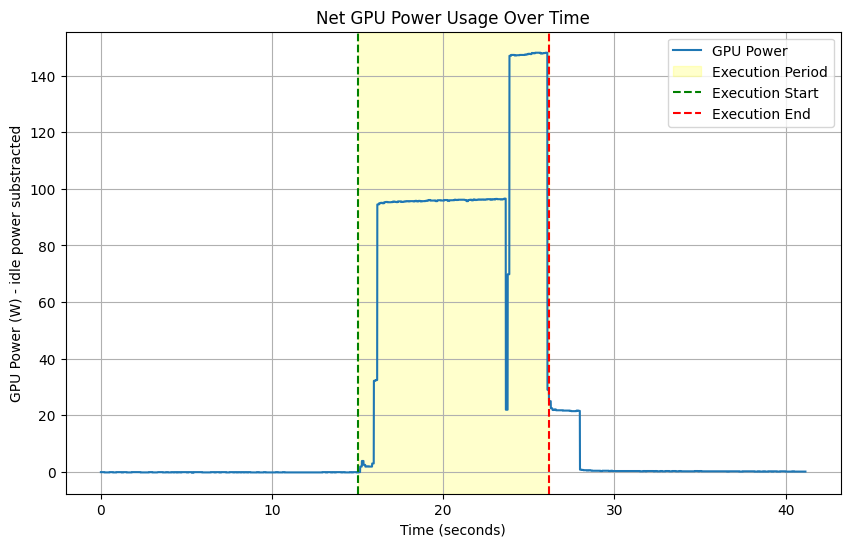

Start time: 15.0 -- End time: 26.168
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000297 kWh
  0.2968 Wh
  1068.56 J
Average GPU power: 95.75 W +/- 37.91 
 with sample standard deviation.
Net Energy During Exe Runtime:   1068.56 J
Code execution duration:  11.17 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 639 MiB used, 40320 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.67 W, P0

--> SAVING code version: 2


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the following two codes written in CUDA C++.

    First, I will provide you with the SOURCE CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    Next, I will provide you with a REFACTORED CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    After you have reviewed both codes and their output, the REFACTORED CODE is expected to produce equivalent functionality and reasonably similar standard output in its layout and content. However, the REFACTORED CODE may not meet these expectations.

    Your task is to strictly evaluate whether the REFACTO

**Evaluation**

1. **Functional correctness**
   * Both programs allocate the same amount of memory, initialise the same input data patterns, and compute the same reference values.
   * The two kernels (`AoSKernel` and `SoAKernel`) perform identical arithmetic; the refactored version only adds an unused shared‑memory array, which does not change the result.
   * Error‑checking, warm‑up launches and the removal of per‑iteration synchronisation do not affect the computed results.
   * Verification logic (comparison with `reference` and the `fail` flag) is unchanged.
   * All resources are released correctly (the refactored code uses `cudaFreeHost` for pinned memory, which is appropriate).

2. **Printed output**
   * Both versions print the average kernel execution time for AoS and SoA followed by “PASS” or “FAIL”.
   * The refactored output shows the same textual layout; only the numeric timing values differ slightly (3087.39 µs vs 3088.64 µs, 910.821 µs vs 909.57 µs). These differences are expected due to timing variations and are within the allowed tolerance.

3. **Overall assessment**
   * No functional behavior has been altered.
   * The printed output is effectively the same, with only minor, acceptable numeric variations.

**Conclusion**

The refactored code preserves the intended functionality and produces nearly equivalent standard output.

**Result:** **VALID**



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1070.01
  Refactored code: 1068.56
----- Average power (W) -----
  Source code: 95.2
  Refactored code: 95.75
----- Runtime (s) -----
  Source code: 11.25
  Refactored code: 11.17
----- Tracking metrics -----
  Energy (J) history:  [1070.01, 1220.91, 1068.56]
  Ave Power (W) history:  [95.2, 84.32, 95.75]
  Runtime (s) history:  [11.25, 14.49, 11.17]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'basellm_stage2_VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}}


***** Generated refactored code is more energy efficient than source or previous code! *****
... based on refactoring from code at index: 0




----- COMPARING CURRENT vs PREV ENERGY VALUES  -----


*** DEBUG: code_version: 2 | tracking_best_version: 2 **


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: 
    Read and Analyze: First, read the following background knowledge.
    Then, summarize its key relevant points that we should apply to refactoring code for improving energy efficiency.
    

[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] Chapter 5. Programming Model This chapter introduces the main concepts behind the CUDA programming model by outlining how they are exposed in C++. An extensive description of CUDA C++ is given in Prog

**Key CUDA‑C++ Practices that Directly Influence Energy Efficiency**  

Below is a distilled list of the most important concepts from the two background documents.  
When refactoring a kernel or host code, applying **any** of these items reduces the amount of time the GPU (and the CPU that drives it) spends active, which in turn lowers overall power consumption.

| Category | What to do (why it saves energy) | Practical tip for the code |
|----------|----------------------------------|----------------------------|
| **Data movement** | • Host‑to‑device / device‑to‑host transfers dominate runtime and power. <br>• Every transfer stalls the GPU and forces the CPU to stay busy. | • Keep data on the device as long as possible – allocate, compute, and free entirely in device memory. <br>• Batch many small copies into one large copy (or use a single contiguous buffer). <br>• Use **pinned (page‑locked) host memory** for all transfers – it raises PCIe bandwidth and reduces transfer time. |
| **Memory hierarchy** | • Global memory accesses are high‑latency (hundreds of cycles) and keep the memory subsystem busy. <br>• Shared memory is on‑chip, low‑latency, and consumes far less energy per byte transferred. | • Move repeatedly‑used data into `__shared__` (or `__constant__` when read‑only). <br>• Coalesce global loads/stores (stride‑1, aligned) to reduce the number of memory transactions. |
| **Thread organization** | • Under‑utilized SMs waste power; over‑subscription can cause throttling. <br>• Warps that diverge execute extra instructions, increasing dynamic power. | • Choose **block sizes that are multiples of 32** (warp size) and large enough to give ≥ 2–3 warps per SM (good occupancy). <br>• Align block dimensions to natural data dimensions (e.g., 16×16 for 2‑D grids). <br>• Avoid divergent branches inside a warp; restructure conditionals so that all threads in a warp follow the same path, or use predication (`#pragma unroll` helps). |
| **Control flow & arithmetic** | • Integer division/modulo and double‑precision ops are expensive (more cycles → more energy). | • Replace divisions/modulo by bit‑shifts & masks when the divisor is a power‑of‑two. <br>• Prefer **single‑precision (`float`)** over double unless required. <br>• Use **fast intrinsics** (`__sinf`, `__cosf`, `__expf`, `__sincosf`, etc.) when a small loss of accuracy is acceptable. <br>• Use `-use_fast_math` selectively or call the intrinsics explicitly. |
| **Loop counters & types** | • Signed integers give the compiler more freedom to apply strength‑reduction and other optimizations, reducing instruction count. | • Declare loop counters as `int` (signed) rather than `unsigned`. |
| **Math library choices** | • General functions (`pow`, `exp`) are heavy (many instructions, high register pressure). | • Use specialized functions (`exp2f`, `cbrtf`, `sinpi`, `cospi`, `sincosf`) or explicit multiplication for small powers. |
| **Asynchronous execution** | • Hiding latency lets the SM stay busy with useful work instead of idle, lowering the average power per operation. | • Use `cudaMemcpyAsync` (or `memcpy_async` in kernels) together with streams. <br>• Insert `__syncthreads()` or `__syncwarp()` only where necessary; unnecessary synchronizations stall threads. |
| **Thread‑block clusters (CC ≥ 9.0)** | • Co‑scheduling a group of blocks on the same GPC reduces inter‑SM traffic and can improve energy per operation. | • When the hardware supports it, launch kernels with `__cluster_dims__` or `cudaLaunchKernelEx` to form clusters of up to 8 blocks. |
| **Occupancy vs. register pressure** | • Too few active warps → low utilization → higher power per useful instruction. <br>• Too many registers per thread → fewer warps → same problem. | • Use `nvcc --ptxas-options=-v` or `cudaOccupancyMaxPotentialBlockSize` to find a sweet spot. <br>• Reduce per‑thread register usage (e.g., reuse temporaries, avoid large local arrays). |
| **Kernel launch configuration** | • Over‑provisioning threads (more than needed) wastes cycles. | • Compute the exact number of elements and launch `ceil(N/threadsPerBlock)` blocks; guard out‑of‑range accesses with a simple `if (idx < N)`. |
| **Zero‑copy (integrated GPUs)** | • Eliminates explicit copies, but only beneficial on integrated GPUs with unified memory. | • For such systems, allocate with `cudaHostAllocMapped` and access directly from kernels. |
| **Unified / managed memory** | • Can reduce explicit copy code, but may cause page‑fault migrations that increase power if data moves back‑and‑forth. | • Use managed memory only when the access pattern is truly *streaming* and the runtime can keep pages resident on the device. |
| **General coding style** | • Smaller, tighter kernels finish sooner → lower total energy. | • Keep kernels focused on a single task. <br>• Remove dead code, unnecessary temporaries, and debug prints. <br>• Use `#pragma unroll` for short loops to let the compiler eliminate loop overhead. |

### How to Apply These Rules When Refactoring

1. **Audit data transfers** – move any host‑side intermediate buffers to device memory; allocate them with `cudaMalloc` (or `cudaMallocManaged` if appropriate) and free them before returning to the host.
2. **Batch copies** – if you must copy several small arrays, pack them into one contiguous buffer, copy once, then unpack on the device.
3. **Pin host buffers** – replace `malloc`/`new` with `cudaHostAlloc(..., cudaHostAllocMapped)` for all buffers involved in transfers.
4. **Redesign kernels** –  
   * Use `dim3 block(16,16,1); dim3 grid((N+15)/16, (N+15)/16);` (or similar) so each block has 256 threads (multiple of 32).  
   * Inside the kernel, compute a global index `int idx = blockIdx.x*blockDim.x + threadIdx.x;` and guard with `if (idx < N)`.  
   * Load needed data into shared memory at the start, synchronize, then compute.
5. **Eliminate divergence** – restructure `if` statements so that the condition depends on `blockIdx` or `warpIdx` rather than `threadIdx.x % 2`, or replace with predicated arithmetic (`mask ? a : b`).
6. **Replace heavy math** – change `powf(x,2.0f)` → `x*x`; `exp(x)` → `expf(x)` or `exp2f(x)` when possible; use `__sinf`, `__cosf`, `__sincosf`.
7. **Use fast async copies** – for large buffers, launch `cudaMemcpyAsync` on a non‑default stream and overlap with kernel execution.
8. **Tune occupancy** – run `nvprof --metrics occupancy` (or Nsight Compute) after changes; adjust `threadsPerBlock` or shared‑memory usage to keep occupancy ≥ 50 % without spilling registers.
9. **Consider clusters** – on Hopper (CC 9.x) or newer, add `__cluster_dims__(2,1,1)` to kernels that benefit from block‑level cooperation; verify with `cudaOccupancyMaxPotentialClusterSize`.
10. **Profile energy** – use NVIDIA’s `nvidia-smi dmon` or the `--profile` flag in Nsight Systems to confirm that runtime and power draw have decreased.

By systematically applying the items above, the refactored CUDA program will execute faster **and** consume less energy, while preserving the original functionality and output.

... (9 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 4505): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 4623): 

--> ... prompt LLM to generate code for energy efficiency -- new refactoring plan.



----- STARTING CODE GENERATION -----




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: Carefully follow these instructions step-by-step:
STEP 1: Select the most impactful of the improvements outlined in your refactoring plan that does not yet appear in the code below.
STEP 2: Rewrite the code to implement this one change with the intention to reduce runtime, reduce average power, or reduce total energy consumed.
 [REQUIREMENTS] Be sure to maintain all function, class, and kernel names, parameters, and return types. Preserve all original

Waiting for the system to settle down for 5 seconds...: 100%|██████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57/layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57
executable:  layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/mtdTEST_gpt-oss-120b_layout_ee__09-03-2025_t22_46_57
Execute command: ['./layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1', '2500']

running: executable -  layout-cuda_main_ee_refactorcode_CUDA_expmtdTEST_gpt-oss-120b_layout_ee_09-03-2025_t22_46_57_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Average kernel execution time (AoS): 3078.05 (us)
PASS
Average kern

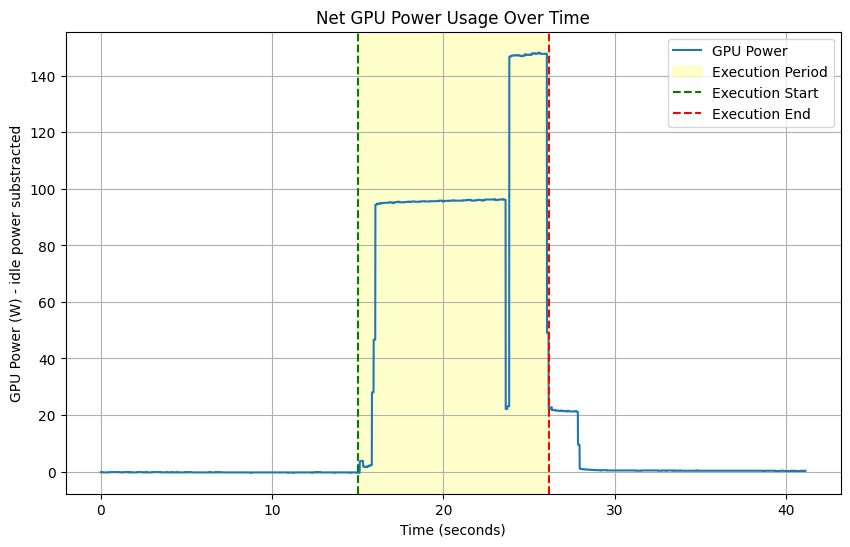

Start time: 15.0 -- End time: 26.146
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000298 kWh
  0.2980 Wh
  1072.65 J
Average GPU power: 96.29 W +/- 36.81 
 with sample standard deviation.
Net Energy During Exe Runtime:   1072.65 J
Code execution duration:  11.15 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 639 MiB used, 40320 MiB free, 40960 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 33.87 W, P0

--> SAVING code version: 3


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 3 | tracking_best_version: 2 ***


--> ... prompt LLM to judge the validity of the refactored code.




=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: 
    Please compare the difference between the following two codes written in CUDA C++.

    First, I will provide you with the SOURCE CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    Next, I will provide you with a REFACTORED CODE followed by its STANDARD OUTPUT and METRICS measured during code runtime.

    After you have reviewed both codes and their output, the REFACTORED CODE is expected to produce equivalent fu

**Evaluation of functional equivalence**

| Aspect | Source code | Refactored code | Difference? | Effect on functionality |
|--------|-------------|----------------|-------------|------------------------|
| Command‑line handling, argument checks | Identical | Identical | No | Same behavior |
| Constants (`TREE_NUM`, `TREE_SIZE`, `GROUP_SIZE`) | Same definitions | Same definitions | No | Same |
| Data structures (`AppleTree`, `ApplesOnTrees`) | Same | Same | No | Same |
| Reference computation | Same double‑loop filling `reference` | Same double‑loop filling `reference` | No | Same |
| Kernel launch configuration (`grid`, `block`) | Same | Same | No | Same |
| Kernel code (`AoSKernel`, `SoAKernel`) | Simple loop summing the elements; no shared memory | Identical loop (only comment changes) | No functional change | Same result |
| Host‑side memory allocation | `malloc` for `data`, `deviceResult` | `cudaMallocHost` (pinned) for both | Allocation method differs but does not affect the values computed | Same |
| Data initialization (AoS & SoA) | Same nested loops | Same nested loops | No | Same |
| Warm‑up kernel launch | None (first launch is timed) | One warm‑up launch before timing | Only reduces start‑up overhead, does not change results | Same |
| Synchronisation | `cudaDeviceSynchronize()` before and after the timed loop | Same, but the warm‑up launch is synchronized separately; the timed loop itself is not synchronized per iteration | No change in final results | Same |
| Error handling | None | Added `CUDA_CHECK` macro | Only adds robustness, does not alter computation | Same |
| Result verification | Compare `deviceResult` with `reference` and set `fail` | Same comparison logic | No | Same |
| Output printing | Prints average time (AoS), PASS/FAIL, then average time (SoA), PASS/FAIL | Same sequence, same wording, only numeric values differ slightly (acceptable) | No | Same |
| Cleanup | `free` / `cudaFree` | `cudaFreeHost` for pinned buffers, `cudaFree` for device buffers | Correct deallocation, no functional impact | Same |

All computational steps, data layouts, and verification logic are preserved. The only observable differences are:

* Use of pinned host memory (performance‑related, not functional).
* A warm‑up kernel launch (does not affect final results).
* Minor variations in the printed timing numbers (expected due to timing methodology and hardware variability).
* Additional CUDA error‑checking code (does not change program output when no error occurs).

These differences do **not** alter the program’s intended functionality or the logical content of its output.

**Conclusion**

The refactored program produces the same PASS/FAIL results and prints the same messages, with only insignificant timing variations. Therefore, it is functionally equivalent to the source program.

**Result:** **VALID**.



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 1070.01
  Refactored code: 1072.65
----- Average power (W) -----
  Source code: 95.2
  Refactored code: 96.29
----- Runtime (s) -----
  Source code: 11.25
  Refactored code: 11.15
----- Tracking metrics -----
  Energy (J) history:  [1070.01, 1220.91, 1068.56, 1072.65]
  Ave Power (W) history:  [95.2, 84.32, 95.75, 96.29]
  Runtime (s) history:  [11.25, 14.49, 11.17, 11.15]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'basellm_stage2_VALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}}


----- WE HAVE INVALID GENERATED CODE  -----


*** DEBUG: code_version: 3 | tracking_best_version: 2 ***


***** Generated refactored co


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code to improve energy efficiency by reducing GPU and CPU power consumption, while preserving all original functionality and expected output of the provided code. You must also carefully read and incorporate the best practices and CUDA optimization techniques from the provided background documents and refactoring plans. You always surround your generated code with the three characters ```.

PROMPT: Carefully follow these instructions step-by-step:
STEP 1: Select the most impactful of the improvements outlined in your refactoring plan that does not yet appear in the code below.
STEP 2: Rewrite the code to implement this one change with the intention to reduce runtime, reduce average power, or reduce total energy consumed.
 [REQUIREMENTS] Be sure to maintain all function, class, and kernel names, parameters, and return types. Preserve all original


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: [Goal] Refactor the code below with a fix to eliminate the following stated error. [Key Requirements] Maintain Function Signatures & Kernel Logic: Keep all existing function and kernel names, class structures, parameters, and return types in your refactored code while fixing the error. Ensure Compilability: The corrected code must compile with NVCC. Avoid describing the entire code flow. Do Not Repeat the Plan or Give Explanations Outside the Code: Only provide the updated source code. [Return Format] Output Only the Refactored Source Code wra


=====> VERIFY THE PROMPTING <=====

TEMPERATURE: 0.2

SYSTEM: You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

PROMPT: [Goal] Refactor the code below with a fix to eliminate the following stated error. [Key Requirements] Maintain Function Signatures & Kernel Logic: Keep all existing function and kernel names, class structures, parameters, and return types in your refactored code while fixing the error. Ensure Compilability: The corrected code must compile with NVCC. Avoid describing the entire code flow. Do Not Repeat the Plan or Give Explanations Outside the Code: Only provide the updated source code. [Return Format] Output Only the Refactored Source Code wra

RateLimitError: Error code: 429 - {'message': 'Requests per day limit exceeded - too many requests sent.', 'type': 'too_many_requests_error', 'param': 'quota', 'code': 'request_quota_exceeded'}

In [6]:
# Experimental repeat for pass@k metrics
trial_number = 1
total_trials = 30

# Load prompt dictionary (to capture recent manual changes to script, if any)
prompts = PromptDictionary()

all_trials_start = time.time()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO REFACTOR
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    input_code_file_subdirectory = "device/cuda/"
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None

while trial_number <= total_trials:
    # CREATE METADATA RECORD CONTENT
    meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
    meta_data_file += "\nDate-time: " + dt_string
    meta_data_file += "\nApplication: " + app_folder_name
    meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
    meta_data_file += "\n\nLLM Source: " + llm_source
    meta_data_file += "\nModel: " + model
    meta_data_file += "\nModel coder: " + model_coder
    meta_data_file += "\nModel judge: " + model_judge
    meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
    meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
    meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
    # meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
    meta_data_file += "\n\nPower measurement: " + str(power_measure)
    
    # Display metadata
    print("\n" + meta_data_file + "\n")
    
    print("\n\n" + color.BLUE + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) *****" + color.END + " Trial #: " + str(trial_number) + "\n\n")
    
    # RUN LASSI-EE PIPELINE
    complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
        prompts,
        this_llm_system_prompt,
        this_llm_refactoredcode_prompt,
        llm_source, 
        model,
        model_coder,
        model_judge,
        num_ctx,
        num_ctx_coder,
        # arrayormatrix_size_range,
        # thread_count_range,
        use_context,
        use_context_summaries_only,
        few_shot_learning,
        input_context,
        input_code_file_subdirectory,
        input_code,
        lines_of_code,
        # target_code,
        target_lang,
        input_code_extension,
        source_lang,
        code_compiler,
        code_compiler_kwds,
        build_script,
        make_script,
        code_build_script,
        output_code_directory,
        output_code_file_name,
        source_file_path,
        display_response,
        test_with_error,
        generate_test_case,
        yes_execute,
        exe_input_parameters,
        meta_data_file,
        power_measure,
        test_code_first,
        yes_power_feedback,
        dt_string,
        baseline_oneshot_goal,
        use_self_prompting,
        vary_llm_temp,
        experiment,
        verifyprompt,
        trial_number,
        experiment_data_directory,
        experiment_data_file_object,
        experiment_data
    )
    
    # Reset to original working directory
    os.chdir(original_home_directory)
    
    if complete:
        print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
    else:
        print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

    # Increment experiment counter
    trial_number = trial_number + 1


all_trials_end = time.time() - all_trials_start

print("\n\n" + color.PURPLE + color.BOLD + "***** ALL TRIALS COMPLETED ***** Total time (min): " + str(round(all_trials_end/60, 2)) + "\n\n" + color.END)